In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [12]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer,bi
from sklearn.naive_bayes import MultinomialNB,BernoulliNB
from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score)

In [13]:
train_data=fetch_20newsgroups(
    subset="train",
    remove=("headers","footers","quotes"))

In [15]:
test_data=fetch_20newsgroups(
    subset="test",
    remove=("headers","footers","quotes"))

In [16]:
x_train_text=train_data.data
y_train=train_data.target
x_test_text=test_data.data
y_test=test_data.target
class_names=train_data.target_names

In [23]:
vectorizer=CountVectorizer(
    stop_words="english",
    min_df=2,
)
x_train=vectorizer.fit_transform(x_train_text)
x_test=vectorizer.transform(x_test_text)


In [24]:
mnb=MultinomialNB()
mnb.fit(
    x_train,
    y_train)
y_pred_mnb=mnb.predict(
    x_test)
    

In [29]:
binary_vectorizer=CountVectorizer(
    stop_words="english",
    min_df=2,
binary=True)
x_train_binary=binary_vectorizer.fit_transform(x_train_text)
x_test_binary=binary_vectorizer.transform(x_test_text)


In [30]:
bnb=BernoulliNB()
bnb.fit(
    x_train_binary,
    y_train)
y_pred_bnb=bnb.predict(
    x_test_binary)
    
    

In [61]:
results=pd.DataFrame({
    "Model":[
        "MultinomialNB",
       "BernoulliNB"],
"Precision":[precision_score(y_test,y_pred_mnb,average="macro"),precision_score(y_test,y_pred_bnb,average="macro")],    
"Accuracy":[accuracy_score(y_test,y_pred_mnb),accuracy_score(y_test,y_pred_bnb)],
"Recall_score":[recall_score(y_test,y_pred_mnb,average="macro"),recall_score(y_test,y_pred_bnb,average="macro")],
"f1_score":[f1_score(y_test,y_pred_mnb,average="macro"),f1_score(y_test,y_pred_bnb,average="macro")]})
results
     

,Model,Precision,Accuracy,Recall_score,f1_score
0,MultinomialNB,0.634470,0.651089,0.636933,0.617859
1,BernoulliNB,0.616678,0.485130,0.469434,0.467865


In [38]:
print("="*40)
print("Evaluation Metrics of Multinomial_NB")
print("="*40)
print("Accuracy score",accuracy_score(y_test,y_pred_mnb))
print("recall score",recall_score(y_test,y_pred_mnb,average="weighted"))
print("f1-score",f1_score(y_test,y_pred_mnb,average="weighted"))


Evaluation Metrics of Multinomial_NB
Accuracy score 0.6510886882634095
recall score 0.6510886882634095
f1-score 0.6296441343359875


In [52]:
print("="*40)
print("Evaluation Metrics of Multinomial_NB")
print("="*40)
print("Accuracy score",accuracy_score(y_test,y_pred_bnb))
print("recall score",recall_score(y_test,y_pred_bnb,average="macro"))
print("f1-score",f1_score(y_test,y_pred_bnb,average="macro"))


Evaluation Metrics of Multinomial_NB
Accuracy score 0.4851301115241636
recall score 0.46943426113187225
f1-score 0.46786548654913174


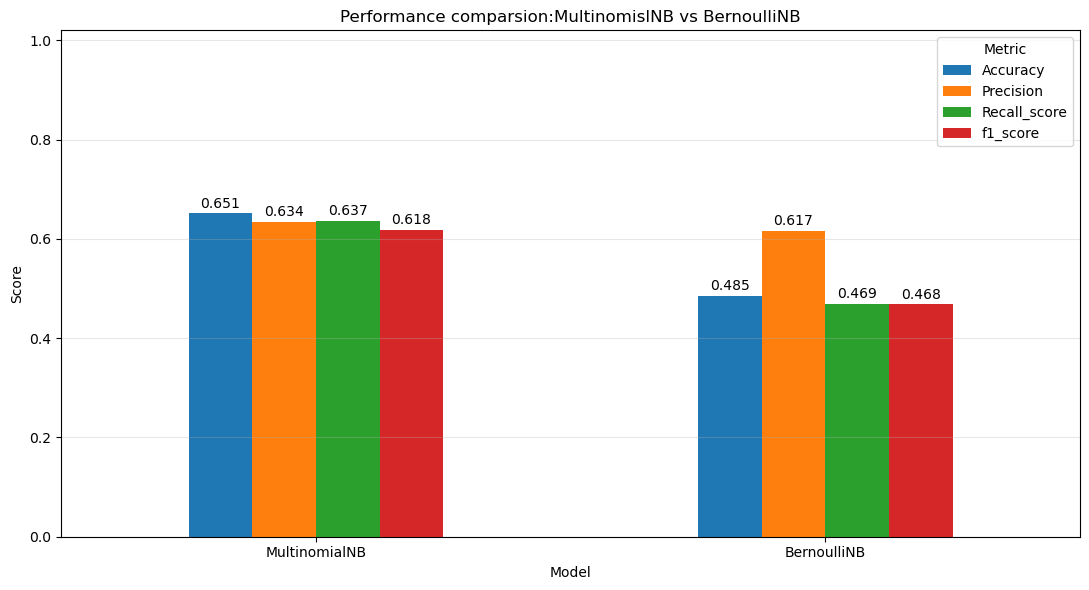

In [66]:
results_metrics=results[
    ["Model","Accuracy","Precision","Recall_score","f1_score"]]
ax=results_metrics.set_index("Model").plot(
    kind="bar",
    figsize=(11,6)
)
plt.title("Performance comparsion:MultinomislNB vs BernoulliNB")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0,1.02)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y",
         alpha=0.3)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2
    )
plt.tight_layout()
plt.show()